In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [5]:
df = pd.read_csv("kc_house_data.csv")

In [6]:
print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
df.info()


First 5 Rows:
           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode  

In [7]:
if "property_age" not in df.columns:
    if "house_age" in df.columns:
        df["property_age"] = df["house_age"]
    elif "yr_built" in df.columns and "sale_year" in df.columns:
        df["property_age"] = df["sale_year"] - df["yr_built"]

In [8]:
if "is_renovated" not in df.columns:
    if "yr_renovated" in df.columns:
        df["is_renovated"] = (
            df["yr_renovated"].fillna(0) > 0
        ).astype(int)

In [9]:
df = df.replace([np.inf, -np.inf], np.nan)

required = [
    "price", "sqft_living", "sqft_lot", "bedrooms",
    "bathrooms", "grade", "condition", "waterfront",
    "lat", "long"
]

for col in required:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required)
df = df[
    (df["price"] > 0) &
    (df["sqft_living"] > 0) &
    (df["sqft_lot"] > 0)
].copy()

In [10]:
if "price_per_sqft_living" not in df.columns:
    df["price_per_sqft_living"] = (
        df["price"] / df["sqft_living"]
    )

if "price_per_sqft_lot" not in df.columns:
    df["price_per_sqft_lot"] = (
        df["price"] / df["sqft_lot"]
    )

In [11]:
df["waterfront_label"] = df["waterfront"].map(
    {0: "No Waterfront", 1: "Waterfront"}
)

print("\nPrepared Dataset Shape:", df.shape)


Prepared Dataset Shape: (21613, 25)


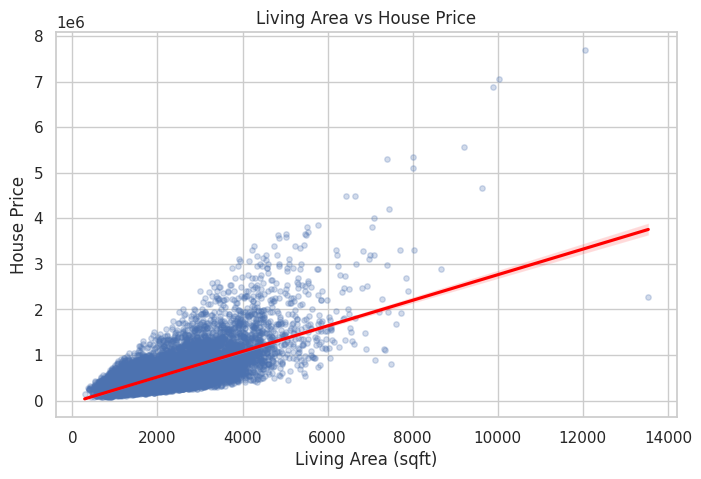

In [12]:
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x="sqft_living",
    y="price",
    scatter_kws={"alpha": 0.25, "s": 15},
    line_kws={"color": "red"}
)
plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.show()

In [13]:
if "property_age" in df.columns:
    plt.scatter(df["property_age"], df["price"])
    plt.xlabel("Property Age")
    plt.ylabel("House Price")
    plt.title("Property Age vs Price")
    plt.show()
elif "house_age" in df.columns:
    plt.scatter(df["house_age"], df["price"])
    plt.xlabel("House Age")
    plt.ylabel("House Price")
    plt.title("House Age vs Price")
    plt.show()

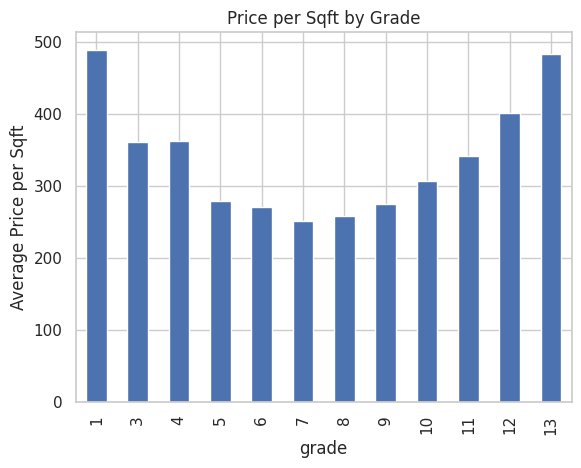

In [14]:
if "price_per_sqft_living" not in df.columns:
    df["price_per_sqft_living"] = df["price"] / df["sqft_living"]

df.groupby("grade")["price_per_sqft_living"].mean().plot(kind="bar")
plt.title("Price per Sqft by Grade")
plt.ylabel("Average Price per Sqft")
plt.show()

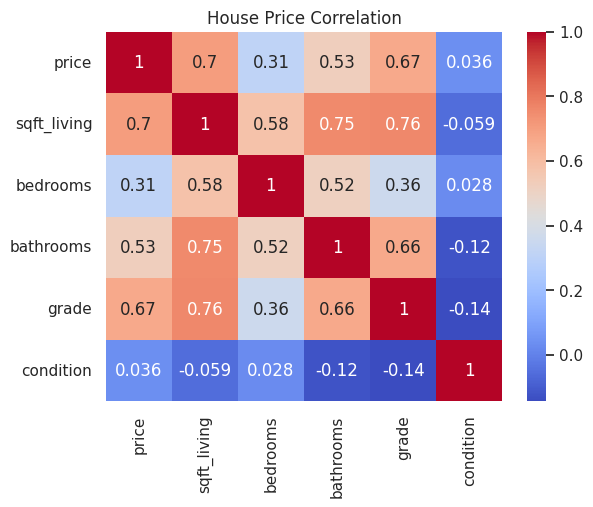

In [15]:
sns.heatmap(
    df[["price", "sqft_living", "bedrooms",
        "bathrooms", "grade", "condition"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("House Price Correlation")
plt.show()

In [16]:
print("Average House Price:", df["price"].mean())
print("Highest House Price:", df["price"].max())
print("Lowest House Price:", df["price"].min())

print("\nMedian Price by Grade:")
print(df.groupby("grade")["price"].median())

Average House Price: 540088.1417665294
Highest House Price: 7700000.0
Lowest House Price: 75000.0

Median Price by Grade:
grade
1      142000.0
3      262000.0
4      205000.0
5      228700.0
6      275276.5
7      375000.0
8      510000.0
9      720000.0
10     914327.0
11    1284000.0
12    1817500.0
13    2983000.0
Name: price, dtype: float64
